## Project analysing government tendered contracts between 2015 and 2026 tendered by the Ministry of Defence.
The purpose is to analyse a number of government tendered contracts available publically from https://www.contractsfinder.service.gov.uk/ relating to the MOD. I aim to identify trends in spending around key inflection points, notable comparing pre and post full scale invasion of Ukraine in Feb 2022.

Data accounts for contracts published as awarded between 01/01/2015 and 24/09/2026

This markdown will contain the scripts used to intake, clean, and analyse data, alongside produce figures and visualisation.


## Setup and Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import os
from pathlib import Path
import re

csv_filenames = []
for dirname, _, filenames in os.walk("./contract_data"):
    for filename in filenames:
        csv_filenames.append(os.path.join(dirname, filename))
    
print(csv_filenames)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

['./contract_data/notices(6).csv', './contract_data/notices(7).csv', './contract_data/notices(9).csv', './contract_data/notices(12).csv', './contract_data/notices(15).csv', './contract_data/notices(4).csv', './contract_data/notices.csv', './contract_data/notices(2).csv', './contract_data/notices(11).csv', './contract_data/notices(10).csv', './contract_data/notices(1).csv', './contract_data/notices(13).csv', './contract_data/notices(14).csv', './contract_data/notices(8).csv', './contract_data/notices(5).csv', './contract_data/notices(3).csv']


## Data Cleaning

In [2]:
chunks = []
row_counts = {}

for path in csv_filenames:
    chunk = pd.read_csv(path, header=0)          
    chunk["source_file"] = Path(path).name        
    row_counts[Path(path).name] = len(chunk)
    chunks.append(chunk)
# parses each file as csv with header, concats them into filestream, creates dataframe at the end
combined = pd.concat(chunks, ignore_index=True)

# --- sanity checks ---
print(combined.shape)
print(pd.Series(row_counts))                       # rows contributed per file
print("duplicate notice IDs:", combined.duplicated(subset="Notice Identifier").sum())
print("column sets consistent:", len({tuple(c.columns) for c in chunks}) == 1)
print((combined.iloc[:, 0] == combined.columns[0]).sum())  # should be 0

combined.drop_duplicates(subset="Notice Identifier", inplace=True)  # remove duplicates
print("duplicate notice IDs after deduplication:", combined.duplicated(subset="Notice Identifier").sum())

print(combined.shape)

(10223, 44)
notices(6).csv     421
notices(7).csv     758
notices(9).csv     654
notices(12).csv    555
notices(15).csv    416
notices(4).csv     793
notices.csv        610
notices(2).csv     521
notices(11).csv    815
notices(10).csv    709
notices(1).csv     681
notices(13).csv    543
notices(14).csv    892
notices(8).csv     474
notices(5).csv     802
notices(3).csv     579
dtype: int64
duplicate notice IDs: 120
column sets consistent: True
0
duplicate notice IDs after deduplication: 0
(10103, 44)


Some duplicate values because I had slightly overlapping data periods. Shape of each file and entry consistent, number of entries after deduplication matches the number of entries retrieved in a search over the same data range on the original website. 

Supplier column contains many different values, plus multiple suppliers sometimes. For the main df we will just extract the supplier names, number of suppliers. Will create a different df focussing on just supplier info like addresses, CH refs, SME or VCE to reduce redundancy and empty columns.

There are a number of fields containing personal information, as well as unnecessary fields like attachments, redundant supplier info. These will be dropped.


In [3]:
# Dealing with supplier information

multi_supplier = combined["Supplier [Name|Address|Ref type|Ref Number|Is SME|Is VCSE]"].str.count(r"\]\[") > 0
print("rows with multiple suppliers:", multi_supplier.sum())

combined_clean = combined

def parse_supplier_names(raw):
    if pd.isna(raw):
        return []
    groups = re.findall(r"\[(.*?)\]", raw, flags=re.DOTALL)
    return [g.split("|")[0].strip() for g in groups]

combined_clean["supplier_names"] = combined["Supplier [Name|Address|Ref type|Ref Number|Is SME|Is VCSE]"].apply(parse_supplier_names)
combined_clean["n_suppliers"] = combined["supplier_names"].apply(len)
combined_clean["supplier_names_joined"] = combined["supplier_names"].apply(lambda lst: "; ".join(lst))


rows with multiple suppliers: 315


In [4]:
# Removing personal information from suppliers and dropping unnecessary columns
personal_info_cols = combined_clean.filter(regex=r"(?i)contact|phone|email|tel|post").columns
print(personal_info_cols.tolist())
combined_clean.drop(columns=personal_info_cols, inplace=True)
combined_clean.drop("Supplier [Name|Address|Ref type|Ref Number|Is SME|Is VCSE]", axis=1, inplace=True)
combined_clean.drop("Attachments", axis=1, inplace=True)
combined_clean["awarded_date"] = pd.to_datetime(combined_clean["Awarded Date"], dayfirst=True, errors="coerce")

combined_clean.head()


['Postcode', 'Contact Name', 'Contact Email', 'Contact Address 1', 'Contact Address 2', 'Contact Town', 'Contact Postcode', 'Contact Country', 'Contact Telephone', 'Contact Website', "Supplier's contact name"]


,Notice Identifier,Notice Type,Organisation Name,Status,Published Date,Title,Description,Nationwide,Region,Cpv Codes,Links,Additional Text,Start Date,End Date,Closing Date,Is sub-contract,Parent Reference,Suitable for SME,Suitable for VCO,Supply Chain,OJEU Contract Type,Value Low,Value High,Awarded Date,Awarded Value,Contract start date,Contract end date,OJEU Procedure Type,Accelerated Justification,Closing Time,source_file,supplier_names,n_suppliers,supplier_names_joined,awarded_date
0,ARTYSYS/00260,Contract,MINISTRY OF DEFENCE,Awarded,2020-12-16T17:14:56Z,Dismounted Joint Fires Integrator (D-JFI),"The Artillery Systems Team, part of DE&S, ran ...",NaN,NaN,35720000,NaN,NaN,10/12/2020,31/03/2026,18/10/2019,NO,NaN,Yes,No,No,Products,1.008735e+08,NaN,10/12/2020,1.008735e+08,18/01/2021,31/03/2026,CompetitiveProcedureWithNegotiationOJEU,NaN,00:00,notices(6).csv,[ELBIT SYSTEMS UK LIMITED],1,ELBIT SYSTEMS UK LIMITED,2020-12-10
1,701377373,Contract,MINISTRY OF DEFENCE,Awarded,2021-01-04T11:06:43Z,Provision of a Temporary Programme Manager to ...,Transparency notice for award of contract plac...,NaN,South East,72224000,NaN,NaN,01/01/2021,30/09/2021,15/12/2020,NO,NaN,Yes,No,No,Services,2.400000e+05,NaN,22/12/2020,2.400000e+05,01/01/2021,30/09/2021,CallOffFromFrameworkAgreement,NaN,10:00,notices(6).csv,[JACOBS U.K. LIMITED],1,JACOBS U.K. LIMITED,2020-12-22
2,701300387,Contract,MINISTRY OF DEFENCE,Awarded,2021-01-05T16:20:10Z,Queen Elizabeth Carrier Personnel Accounting a...,TRANSPARENCY PURPOSE ONLY - Contract Award - T...,NaN,NaN,35113000,NaN,NaN,01/01/2021,31/03/2021,09/12/2020,NO,NaN,Yes,No,No,Products,3.504420e+05,NaN,18/12/2020,3.504420e+05,01/01/2021,31/03/2021,NegotiatedProcedureWithoutPriorPublicationOJEU,NaN,09:00,notices(6).csv,[KINSETSU LIMITED],1,KINSETSU LIMITED,2020-12-18
3,701400373,Contract,MINISTRY OF DEFENCE,Awarded,2021-01-06T17:33:24Z,Provision of External Support for Portsmouth N...,This is a VOLUNTARY TRANSPARENCY NOTICE ONLY t...,NaN,NaN,79410000,NaN,NaN,04/01/2021,30/04/2021,18/12/2020,NO,NaN,Yes,No,No,Services,2.500000e+05,NaN,22/12/2020,2.500000e+05,04/01/2021,30/04/2021,CallOffFromFrameworkAgreement,NaN,10:00,notices(6).csv,[PA CONSULTING SERVICES LIMITED],1,PA CONSULTING SERVICES LIMITED,2020-12-22
4,DD/IT/SVCS/005,Contract,MINISTRY OF DEFENCE,Awarded,2021-01-07T08:19:50Z,DBS FHRS Procurement of Hardware & Software,DBS FHRS Procurement of Hardware & Software,NaN,NaN,30000000,NaN,NaN,16/12/2020,08/01/2021,30/11/2020,NO,NaN,Yes,No,No,Products,9.996649e+04,NaN,15/12/2020,9.996649e+04,16/12/2020,08/01/2021,CallOffFromFrameworkAgreement,NaN,12:00,notices(6).csv,[PROBRAND LIMITED],1,PROBRAND LIMITED,2020-12-15


In [ ]:
# Checking new datetime column 
print(combined_clean["awarded_date"].dtype)                    # should be datetime64
print(combined_clean["awarded_date"].isna().sum())              # how many failed to parse
print(combined_clean.loc[combined_clean["awarded_date"].isna(), "Awarded Date"].unique()) 
print(combined_clean["awarded_date"].min(), combined_clean["awarded_date"].max()) 

datetime64[us]
2
<StringArray>
[nan]
Length: 1, dtype: str
2003-02-16 00:00:00 2026-12-18 00:00:00


In [ ]:
# Identifying weird dates outside the expected range
weird = combined_clean[(combined_clean["awarded_date"].dt.year < 2014) | (combined_clean["awarded_date"].dt.year > 2026)]
print(weird[["Notice Identifier", "Title", "awarded_date"]].to_string())

                       Notice Identifier                                                                                                                                          Title awarded_date
4338                         BIP52786504                                                                 Support, Repair and Calibration of RAF General Purpose Automatic Test Systems.   2008-03-29
4408                         BIP53788620                                                                              Supply and In Service Support for Medium Aircraft Towing Tractors   2008-01-18
4480                         BIP54933687                                                                                    Repair of AMOS MK2 Consoles and Type 417F Oxygen Regulators   2012-03-31
4594                         BIP57151196                                                             Technical Support Services for Aircrew Clothing, Liferafts & Associated Equipments   2011-04-01
4595           

There are a few strange values when organising data based on the awarded date. This is a human entered value so most likely just input error when creating the record. Published date might be more reliable as it's likely a system generated value rather than human input. Here I will compare the publishing and award dates and create a flag for rows with large time lag between award and publishing dates.

In [8]:
# how many pre-2015 dates exist in each column?
print("awarded_date pre-2015:", (combined_clean["awarded_date"].dt.year < 2015).sum())

pub = pd.to_datetime(combined_clean["Published Date"], utc=True).dt.tz_localize(None)
print("published_date pre-2015:", (pub.dt.year < 2015).sum())
print("published_date range:", pub.min(), pub.max())

awarded_date pre-2015: 31
published_date pre-2015: 0
published_date range: 2015-03-05 12:50:22 2026-09-24 10:34:34


In [9]:
# calculating lag between published date and awarded date
pub = pd.to_datetime(combined_clean["Published Date"], utc=True).dt.tz_localize(None)

combined_clean["lag_days"] = (combined_clean["awarded_date"] - pub).dt.days
combined_clean["award_year"] = combined_clean["awarded_date"].dt.year
print(combined_clean.groupby("award_year")["lag_days"].median())
print(combined_clean.groupby("award_year")["lag_days"].mean())
print(combined_clean.groupby("award_year")["lag_days"].std())

award_year
2003.0   -6100.5
2004.0   -4698.0
2005.0   -4166.0
2006.0   -4244.0
2008.0   -3346.0
2011.0   -2358.0
2012.0   -2029.0
2013.0   -1591.0
2014.0    -229.0
2015.0     -23.0
2016.0     -15.0
2017.0     -20.0
2018.0     -17.0
2019.0     -21.0
2020.0     -25.0
2021.0     -20.0
2022.0     -28.0
2023.0     -22.0
2024.0     -20.0
2025.0     -22.0
2026.0     -20.0
Name: lag_days, dtype: float64
award_year
2003.0   -6100.500000
2004.0   -4764.333333
2005.0   -4166.000000
2006.0   -4244.000000
2008.0   -3346.000000
2011.0   -2406.000000
2012.0   -2029.000000
2013.0   -1591.000000
2014.0    -288.866667
2015.0     -54.635211
2016.0     -27.646774
2017.0     -49.104587
2018.0     -50.084063
2019.0     -48.170940
2020.0    -108.470524
2021.0     -49.748357
2022.0     -68.008607
2023.0     -42.198777
2024.0     -37.547507
2025.0     -40.560948
2026.0     -20.871972
Name: lag_days, dtype: float64
award_year
2003.0    1822.214175
2004.0     185.613398
2005.0            NaN
2006.0            Na

There are some instances where the published date and awarded date differ greatly, with many where the awarded date is in years preceding the range of the data available (which started in 2015). Some of these are likely input errors. For awarded dates between 2015 and 2026, the lag days were relatively stable, with stdev never more than 210 days, means and medians within range of 1-2 months. Firstly, the negative means and median values imply that a contract is awarded first, then details are published later. Second, for the overwhelming majority of entries, award and publication date are relatively similar. 
I will flag entries where the award dates differ massively from the publication dates, and exclude these from any analysis where award date is used.

In [10]:
# flag anything with an implausible lag, regardless of what year it landed in
lag_threshold_days = 365 # a year seems like a reasonable threshold for an acceptable lag between publication and award date 
combined_clean["lag_flag"] = combined_clean["lag_days"].abs() > lag_threshold_days

print(combined_clean["lag_flag"].sum())
print(combined_clean.loc[combined_clean["lag_flag"], ["Notice Identifier", "Title", "awarded_date", "Published Date", "lag_days"]])

240
                                       Notice Identifier  \
64                                             701479385   
69                                        DIO/CB1/MOD004   
70                                        DIO/CB1/MOD010   
108                                          HOCS4/00015   
219                                              RE21280   
220                                              RE21281   
221                                              RE21282   
296                                          BIP97814349   
364                                            700008125   
386                                 tender_274703/965752   
478                                 tender_278832/975873   
481                                 tender_278797/975998   
483                                 tender_278897/976023   
506                                          FTS5/CCT812   
508                                        RM1043/CCT636   
513                                 

In [11]:
print(combined_clean["lag_days"].isna().sum())
print(combined_clean[combined_clean["lag_days"].isna()]["lag_flag"].unique())  # confirm these show as False, not True

combined_clean[~combined_clean["lag_flag"]].groupby("award_year")["lag_days"].agg(["mean", "median", "std"])

2
[False]


,mean,median,std
award_year,,,
2014.0,-210.538462,-229.0,76.830566
2015.0,-42.804286,-23.0,66.149505
2016.0,-21.127243,-14.0,49.206449
2017.0,-40.588454,-19.0,60.066444
2018.0,-31.293694,-16.0,47.000751
2019.0,-35.731677,-21.0,43.231530
2020.0,-51.465144,-22.0,75.851341
2021.0,-39.645315,-19.5,56.289353
2022.0,-56.369268,-27.0,77.086654


In [ ]:
combined_clean.to_csv("combined_contract_data.csv", index=False)


In [13]:
combined_clean.shape

(10103, 38)

## Exploratory Analysis

The first thing to look at is number of contracts over time. We will do this as a bar chart looking split across months and years.

/tmp/ipykernel_56730/4055046891.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly, x="year_month", y="n_notices", palette=colors_from_values(monthly["n_notices"], "RdYlGn"))
/tmp/ipykernel_56730/4055046891.py:23: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.barplot(data=monthly, x="year_month", y="n_notices", palette=colors_from_values(monthly["n_notices"], "RdYlGn"))


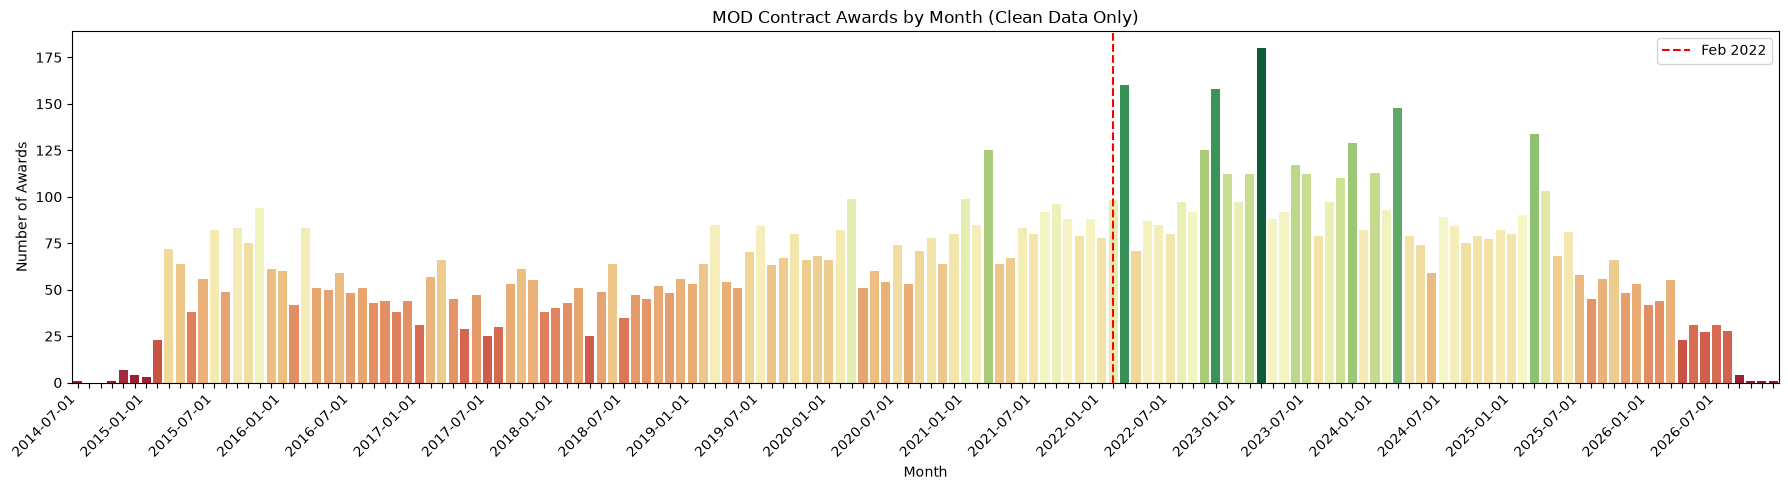

In [ ]:



clean_data = combined_clean[~combined_clean["lag_flag"]].copy()

# collapse to year-month so each period appears once, in chronological order
clean_data["year_month"] = clean_data["awarded_date"].dt.to_period("M").dt.to_timestamp()

monthly = clean_data.groupby("year_month").size().reset_index(name="n_notices")
full_range = pd.date_range(clean_data["year_month"].min(), clean_data["year_month"].max(), freq="MS")
monthly = monthly.set_index("year_month").reindex(full_range, fill_value=0).rename_axis("year_month").reset_index()


plt.figure(figsize=(18, 5))
sns.barplot(data=monthly, x="year_month", y="n_notices", palette=colors_from_values(monthly["n_notices"], "RdYlGn"))

# thin out x-axis labels — otherwise unreadable with 100+ months
ax = plt.gca()
for i, label in enumerate(ax.get_xticklabels()):
    label.set_visible(i % 6 == 0)   # every 6th label, roughly half-yearly
plt.xticks(rotation=45, ha="right")

# mark your event date
event_idx = monthly[monthly["year_month"] == "2022-02-01"].index
if len(event_idx):
    plt.axvline(event_idx[0], color="red", linestyle="--", label="Feb 2022")
    plt.legend()

plt.title("MOD Contract Awards by Month (Clean Data Only)")
plt.xlabel("Month")
plt.ylabel("Number of Awards")
plt.tight_layout()
plt.show()

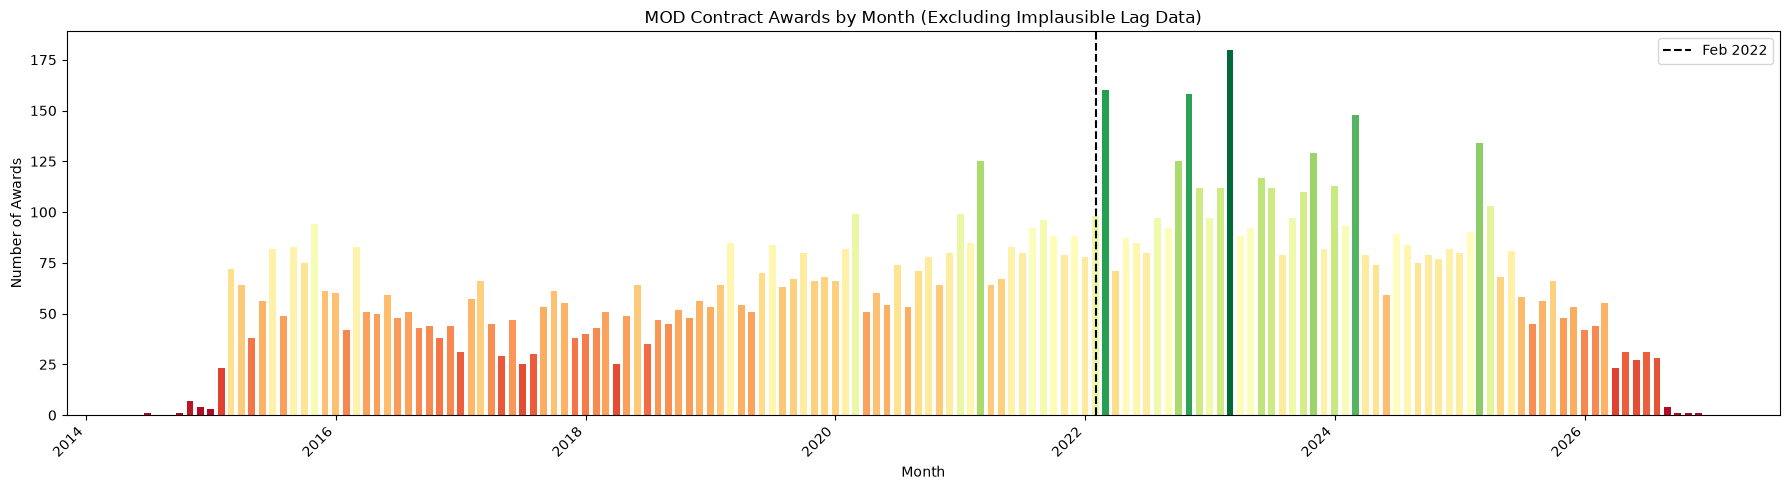

In [ ]:

# Colour values based on y value of the bar, using a seaborn palette
def colors_from_values(values, palette_name):
    # normalize the values to range [0, 1]
    normalized = (values - min(values)) / (max(values) - min(values))
    # convert to indices
    indices = np.round(normalized * (len(values) - 1)).astype(np.int32)
    # use the indices to get the colors
    palette = sns.color_palette(palette_name, len(values))
    return np.array(palette).take(indices, axis=0)


clean_data = combined_clean[~combined_clean["lag_flag"]].copy()

# collapse to year-month so each period appears once, in chronological order
clean_data["year_month"] = clean_data["awarded_date"].dt.to_period("M").dt.to_timestamp()

monthly = clean_data.groupby("year_month").size().reset_index(name="n_notices")
full_range = pd.date_range(clean_data["year_month"].min(), clean_data["year_month"].max(), freq="MS") # fills in missing months with 0s
monthly = monthly.set_index("year_month").reindex(full_range, fill_value=0).rename_axis("year_month").reset_index()


colors = colors_from_values(monthly["n_notices"], "RdYlGn")

plt.figure(figsize=(18, 5))
plt.bar(monthly["year_month"], monthly["n_notices"], color=colors, width=20)

ax = plt.gca()
#for i, label in enumerate(ax.get_xticklabels()):
#    label.set_visible(i % 1 == 0)
plt.xticks(rotation=45, ha="right")

event_idx = monthly[monthly["year_month"] == "2022-02-01"].index
if len(event_idx):
    plt.axvline(monthly["year_month"].iloc[event_idx[0]], color="black", linestyle="--", label="Feb 2022")
    plt.legend()

plt.title("MOD Contract Awards by Month (Excluding Implausible Lag Data)")
plt.xlabel("Month")
plt.ylabel("Number of Awards")
plt.tight_layout()
plt.show()